# 01 - Data Exploration

**Research Objective**

Explore and assess the quality of the three South African fake news datasets before performing topic modeling, semantic categorisation and NER.

**Workflow:**
1. Load the standardised dataset.
2. Inspect schema, dimensions, and sample records.
3. Assess missing values and duplicate articles.
4. Examine test lengths, sources, and publication dates.

## Import Dependencies & Dataset

In [1]:
from pathlib import Path
import sys
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer

from IPython.display import display

PROJECT_ROOT = Path.cwd().parent

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path.cwd()

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

for folder in [FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

logging.basicConfig(level=logging.INFO)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [2]:
df = pd.read_csv('../data/interim/fake_news_combined.csv')

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (584, 6)


,article_id,source,title,text,published_at,url
0,mzanzi_0000001,mzanzi,Video of Masego - Leaked trending video of Masego,A Hoax old video which is believed to be a vid...,2020-04-02 00:00:00+00:00,https://www.mzansistories.com/2020/04/video-of...
1,mzanzi_0000002,mzanzi,FUNERAL UPDATES FOR PASTOR TSHIFHIWA IRENE OF ...,MEMORIAL SERVICE FOR APOSTLE TSHIFHIWA IRENE O...,2018-10-26 00:00:00+00:00,https://www.mzansistories.com/2018/10/funeral-...
2,mzanzi_0000003,mzanzi,Student stabbed to death outside Mondeor High ...,Pupil stabbed to death outside Mondeor High Sc...,2019-03-13 00:00:00+00:00,https://www.mzansistories.com/2019/03/student-...
3,mzanzi_0000004,mzanzi,Before You Slide Into My Inbox Please Check My...,Before You Slide Into My Inbox Please Check My...,2019-05-18 00:00:00+00:00,https://www.mzansistories.com/2019/05/before-y...
4,mzanzi_0000005,mzanzi,Women attacked at Soshanguve crossing mall for...,Watch Video - Women attacked at Soshanguve cro...,2018-11-07 00:00:00+00:00,https://www.mzansistories.com/2018/11/women-at...


## Corpus Overview

Inspect Columns, Data Types & examples from the dataset

In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
display(
    df.dtypes.astype(str).rename("dtype").to_frame()
)

print("\nSample records:")
display(df.sample(
    n=min(5, len(df)),
    random_state=42,
))

print("Descriptive statistics:")
display(df.describe(include="all").T)

Columns:
['article_id', 'source', 'title', 'text', 'published_at', 'url']

Data types:


,dtype
article_id,object
source,object
title,object
text,object
published_at,object
url,object



Sample records:


,article_id,source,title,text,published_at,url
383,sa_news_0000107,sa_news,#HungerGames ANC Police Standing Guard to STOP...,"\""A police vehicle parked in front of the food...",2020-05-15 00:00:00+00:00,https://sa-news.com/hungergames-anc-police-sta...
422,sa_news_0000146,sa_news,"\""Say You Want to Kill Off 95% of The World\"" ...",For all those dedicated yet misled subscribers...,2020-07-04 00:00:00+00:00,https://sa-news.com/say-you-want-to-kill-off-9...
90,mzanzi_0000091,mzanzi,Reasons Why Women Cry or Moan During Sex,"Reasons Why Women Cry or Moan During Sex Yes, ...",2019-04-15 00:00:00+00:00,https://www.mzansistories.com/2019/04/reasons-...
472,sa_news_0000196,sa_news,Small-scale White Farmer & Friend Executed Wit...,"Why would so called \""robbers\"" gruesomely sli...",2020-02-21 00:00:00+00:00,https://sa-news.com/small-scale-white-farmer-f...
522,whatsapp_0000029,whatsapp,Applications for Learnership Posts at BMW,Requirements There are a couple of specific re...,2020-03-05 00:00:00+00:00,http://whatsappgroup.co.za/2020/03/05/applicat...


Descriptive statistics:


,count,unique,top,freq
article_id,584,584,mzanzi_0000001,1
source,584,3,mzanzi,277
title,584,573,Three Persons In critical conditions following...,2
text,583,573,A 25-year-old man was killed last night in an ...,2
published_at,584,350,2019-08-28 00:00:00+00:00,17
url,584,573,http://www.trendsdaily.co.za/metro-new/three-p...,2


,source,article_count
0,mzanzi,277
1,sa_news,217
2,whatsapp,90


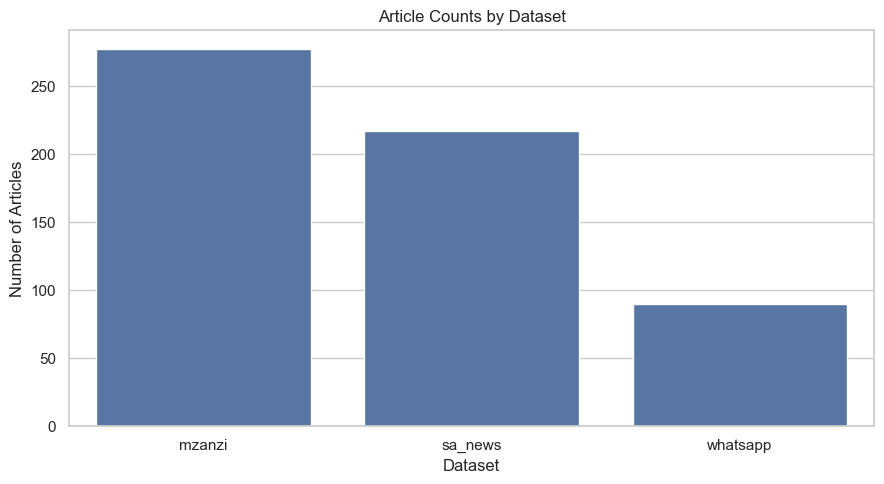

In [4]:
dataset_counts = (
    df.groupby("source")
    .size()
    .reset_index(name="article_count")
)

display(dataset_counts)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=dataset_counts,
    x="source",
    y="article_count"
)

plt.title("Article Counts by Dataset")
plt.xlabel("Dataset")
plt.ylabel("Number of Articles")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "01_dataset_counts.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Dataset Quality

Check for missing values, invalid dates, duplicate IDs and duplicate article text.

In [5]:
missing_summary = (
    df.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

missing_summary["missing_percent"] = (
    100 * missing_summary["missing_count"]
    / max(len(df), 1)
).round(2)

display(
    missing_summary.sort_values(
        "missing_percent",
        ascending=False,
    )
)

,missing_count,missing_percent
text,1,0.17
article_id,0,0.00
source,0,0.00
title,0,0.00
published_at,0,0.00
url,0,0.00


In [6]:
duplicate_summary = pd.DataFrame({
    "measure": [
        "Exact duplicate rows",
        "Duplicate article IDs",
        "Duplicate article text (excluding missing text)",
    ],
    "count": [
        int(df.duplicated().sum()),
        int(df["article_id"].duplicated().sum()),
        int(
            df.loc[
                df["text"].notna(),
                "text",
            ]
            .astype(str)
            .str.strip()
            .str.casefold()
            .duplicated()
            .sum()
        ),
    ],
})

display(duplicate_summary)

,measure,count
0,Exact duplicate rows,0
1,Duplicate article IDs,0
2,Duplicate article text (excluding missing text),10


In [7]:
text_key = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.casefold()
)

duplicate_text_mask = (
    text_key.ne("")
    & text_key.duplicated(keep=False)
)

duplicate_text_examples = df.loc[
    duplicate_text_mask,
    ["article_id", "source", "title", "text"],
].copy()

display(duplicate_text_examples.head(20))

,article_id,source,title,text
513,whatsapp_0000020,whatsapp,POST: CLEANER,Requirements There are a couple of specific re...
522,whatsapp_0000029,whatsapp,Applications for Learnership Posts at BMW,Requirements There are a couple of specific re...
556,whatsapp_0000063,whatsapp,"Race car driver, Jessi Combs killed in high-sp...","Racing driver Jessi Combs, considered the \""fa..."
557,whatsapp_0000064,whatsapp,Soweto Man sentenced to life imprisonment for ...,A 44-year-old Soweto man who shot and killed h...
558,whatsapp_0000065,whatsapp,See the condition a man left a woman’s face in...,"A man battered a woman, leaving her unrecogniz..."
559,whatsapp_0000066,whatsapp,Xenophobia not behind Pretoria chaos: authorities,Tshwane authorities say there’s no evidence li...
560,whatsapp_0000067,whatsapp,ANC confirms Zandile Gumede’s resignation with...,eThekwini mayor Zandile Gumede has withdrawn h...
561,whatsapp_0000068,whatsapp,Three Persons In critical conditions following...,Three people were left critically injured yest...
562,whatsapp_0000069,whatsapp,Just In:-Man killed in alleged hit-and-run.,A 25-year-old man was killed last night in an ...
563,whatsapp_0000070,whatsapp,ANC’s position on Public Protector’s removal a...,The planned removal of the public protector is...


In [8]:
eda_df = df.copy()

eda_df["published_at"] = pd.to_datetime(
    eda_df["published_at"],
    errors="coerce",
    utc=True,
)

valid_dates = eda_df["published_at"].dropna()

print("Publication date summary")
print("------------------------")
print(f"Articles with valid dates: {len(valid_dates):,}")
print(
    f"Articles without valid dates: "
    f"{eda_df['published_at'].isna().sum():,}"
)

if not valid_dates.empty:
    print("Earliest publication date:", valid_dates.min())
    print("Latest publication date:", valid_dates.max())

Publication date summary
------------------------
Articles with valid dates: 583
Articles without valid dates: 1
Earliest publication date: 2016-10-17 00:00:00+00:00
Latest publication date: 2020-12-06 00:00:00+00:00


## Text Characteristics

Inspect article lengths, empty or very short texts, and text cleaning requirements

In [9]:
eda_df["text_clean_for_eda"] = (
    eda_df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

eda_df["text_length_chars"] = (
    eda_df["text_clean_for_eda"].str.len()
)

eda_df["text_length_words"] = (
    eda_df["text_clean_for_eda"]
    .str.split()
    .str.len()
)

# Empty text should have a word count of zero.
eda_df.loc[
    eda_df["text_clean_for_eda"].eq(""),
    "text_length_words",
] = 0

print("Article character count")
display(eda_df["text_length_chars"].describe().to_frame())

print("Article word count")
display(eda_df["text_length_words"].describe().to_frame())

Article character count


,text_length_chars
count,584.000000
mean,2433.489726
std,2179.483380
min,0.000000
25%,939.500000
50%,1651.500000
75%,3307.000000
max,14035.000000


Article word count


,text_length_words
count,584.000000
mean,412.767123
std,369.169311
min,0.000000
25%,158.750000
50%,280.500000
75%,562.250000
max,2388.000000


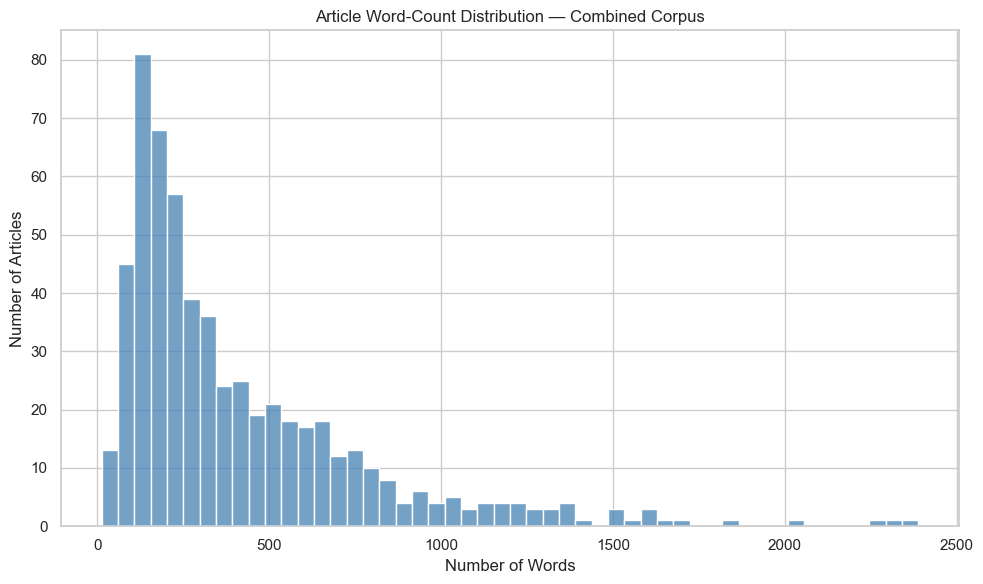

In [10]:
nonempty_articles = eda_df[
    eda_df["text_length_words"] > 0
].copy()

plt.figure(figsize=(10, 6))

sns.histplot(
    data=nonempty_articles,
    x="text_length_words",
    bins=50,
    color="steelblue",
)

plt.title("Article Word-Count Distribution — Combined Corpus")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_overall_word_count_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

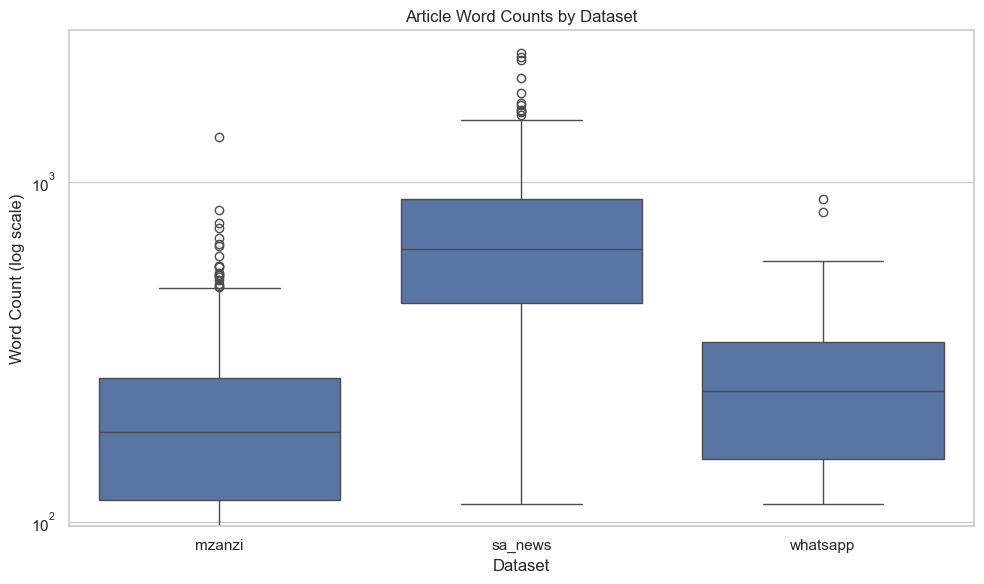

In [19]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=eda_df,
    x="source",
    y="text_length_words",
)

plt.yscale("log")
plt.title("Article Word Counts by Dataset")
plt.xlabel("Dataset")
plt.ylabel("Word Count (log scale)")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "03_text_length_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Temporal Characteristics

Overall publication date distribution and monthly article counts

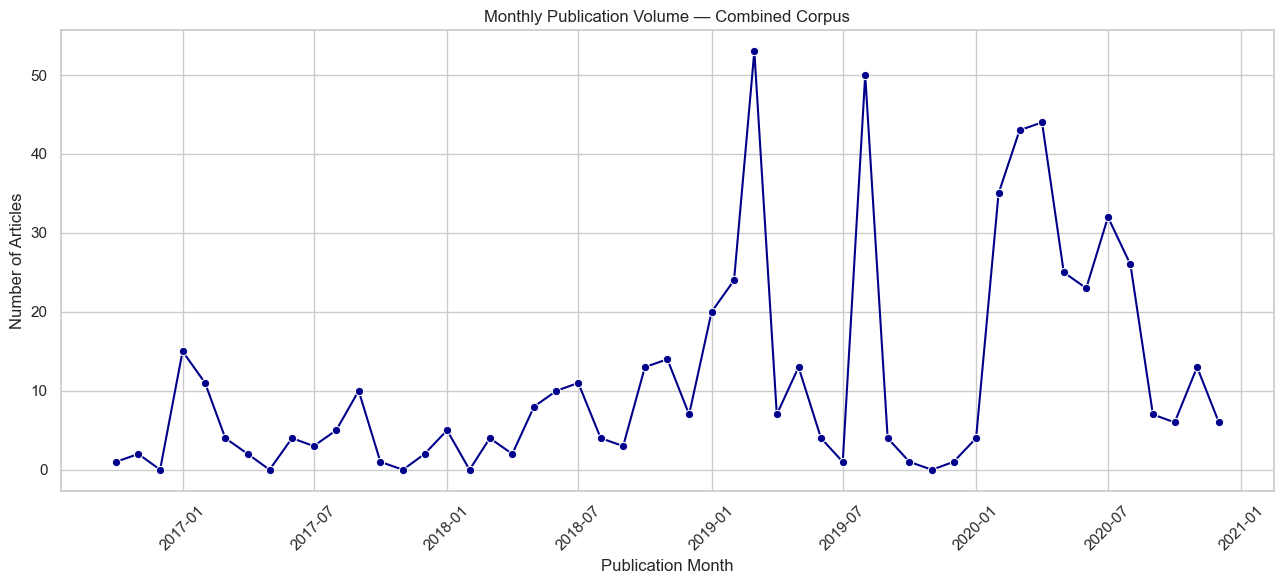

In [12]:
dated_articles = eda_df.dropna(
    subset=["published_at"]
).copy()

monthly_counts = (
    dated_articles
    .set_index("published_at")
    .resample("MS")
    .size()
    .rename("article_count")
    .reset_index()
)

if not monthly_counts.empty:
    plt.figure(figsize=(13, 6))

    sns.lineplot(
        data=monthly_counts,
        x="published_at",
        y="article_count",
        marker="o",
        color="darkblue",
    )

    plt.title("Monthly Publication Volume — Combined Corpus")
    plt.xlabel("Publication Month")
    plt.ylabel("Number of Articles")
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / "04_monthly_publication_volume.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
else:
    print("No valid publication dates available for plotting.")

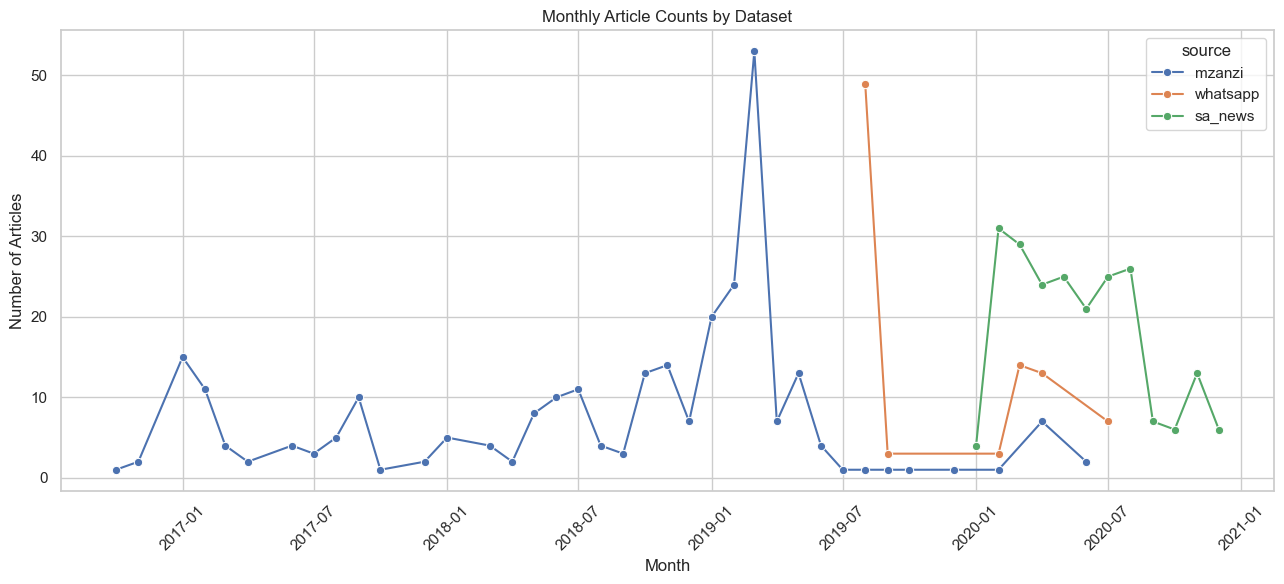

In [14]:
dated_df = df.dropna(
    subset=["published_at"]
).copy()

# Convert published_at to datetime
dated_df["published_at"] = pd.to_datetime(
    dated_df["published_at"],
    errors="coerce",
    utc=True
)

# Remove invalid dates
dated_df = dated_df.dropna(
    subset=["published_at"]
)

# Extract month
dated_df["month"] = (
    dated_df["published_at"]
    .dt.tz_convert(None)
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Count articles per month and source
monthly_counts = (
    dated_df.groupby(["month", "source"])
    .size()
    .reset_index(name="article_count")
)

# Plot
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_counts,
    x="month",
    y="article_count",
    hue="source",
    marker="o",
)

plt.title("Monthly Article Counts by Dataset")
plt.xlabel("Month")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_monthly_counts.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Lexical Exploration

Explore frequent words, bigrams and trigrams as an inital descriptive view

In [15]:
# Use non-empty article text.
texts = (
    eda_df.loc[
        eda_df["text_clean_for_eda"].ne(""),
        "text_clean_for_eda",
    ]
    .tolist()
)

if not texts:
    raise ValueError(
        "No non-empty article text is available for lexical analysis."
    )

vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=30,
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
)

X_words = vectorizer.fit_transform(texts)

word_frequencies = np.asarray(
    X_words.sum(axis=0)
).ravel()

top_words = pd.DataFrame({
    "word": vectorizer.get_feature_names_out(),
    "frequency": word_frequencies,
}).sort_values(
    "frequency",
    ascending=False,
)

display(top_words.head(30))

,word,frequency
1,anc,957
16,people,955
20,said,769
22,south,664
2,black,580
0,africa,546
11,like,518
27,white,476
17,police,475
8,government,383


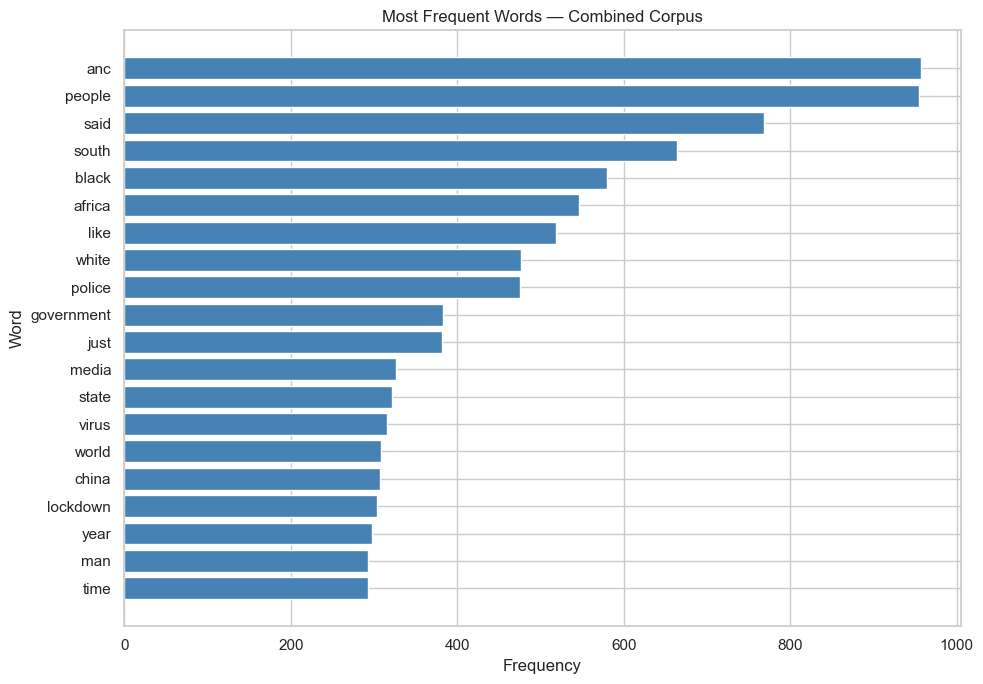

In [16]:
top_20_words = top_words.head(20).sort_values("frequency")

plt.figure(figsize=(10, 7))

plt.barh(
    top_20_words["word"],
    top_20_words["frequency"],
    color="steelblue",
)

plt.title("Most Frequent Words — Combined Corpus")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_top_words.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [17]:
bigram_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(2, 2),
    max_features=30,
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
)

X_bigrams = bigram_vectorizer.fit_transform(texts)

bigram_frequencies = np.asarray(
    X_bigrams.sum(axis=0)
).ravel()

top_bigrams = pd.DataFrame({
    "bigram": bigram_vectorizer.get_feature_names_out(),
    "frequency": bigram_frequencies,
}).sort_values(
    "frequency",
    ascending=False,
)

display(top_bigrams.head(30))

,bigram,frequency
23,south africa,445
4,ccp virus,145
29,year old,131
22,social media,116
24,south african,114
28,white people,95
10,free state,76
25,south africans,75
0,anc government,73
15,mainstream media,72


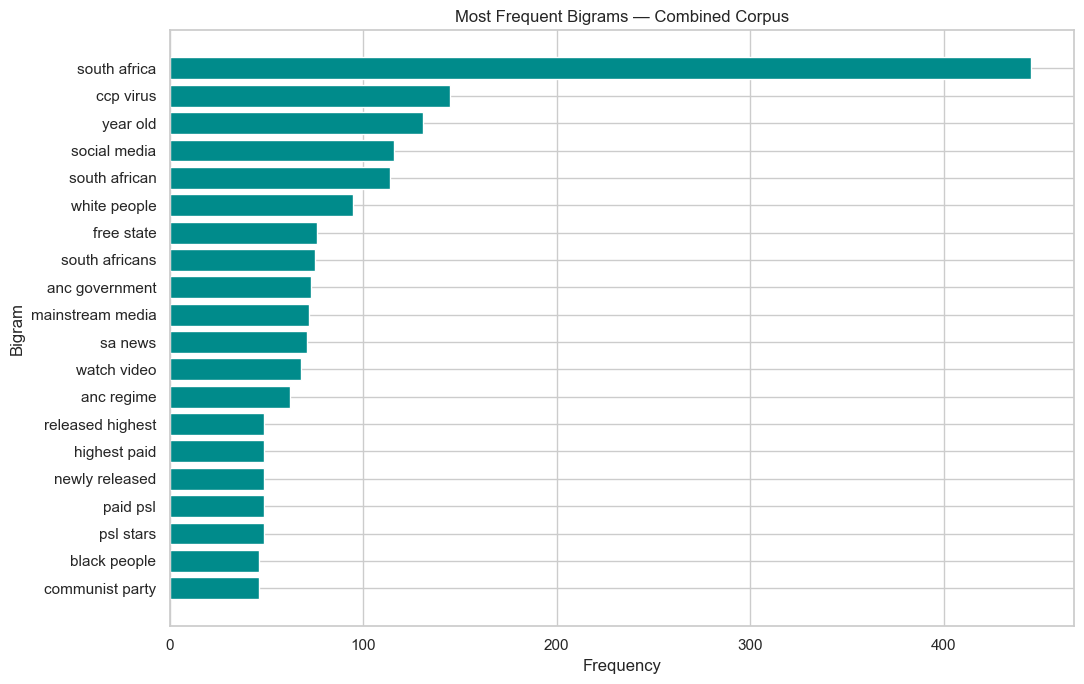

In [18]:
top_20_bigrams = top_bigrams.head(20).sort_values("frequency")

plt.figure(figsize=(11, 7))

plt.barh(
    top_20_bigrams["bigram"],
    top_20_bigrams["frequency"],
    color="darkcyan",
)

plt.title("Most Frequent Bigrams — Combined Corpus")
plt.xlabel("Frequency")
plt.ylabel("Bigram")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "07_top_bigrams.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()